# Spindown, 2026-10-11 -- CW

Same protocol as `spindown_20260913.ipynb`, **with the rotor spinning clockwise** instead
of 09-13's counterclockwise. The rotor was laser-driven to a steady rotation for ~38 h
(drive file front-end GPS 1475632200 -> 1475769325, PD on for 99.6% of it), then the
laser was switched off at front-end GPS **1475769325** (PD ~2418 -> dark in ~1 s,
confirmed in §1) and the rotor coasted freely for the **4.2 h** of the coast file.

Run facts (front-end GPS; the cymac clock runs ahead of true GPS, see CLAUDE.md):

| | 09-13 (CCW) | **10-11 (CW)** |
|---|---|---|
| coast file | 1473375897 -> 1473435502 | **1475768725 -> 1475784000** |
| laser off (`STOP`) | 1473376497 | **1475769325** |
| record after laser-off | 16.6 h | **4.2 h** |
| PD level while driven | ~404 counts | **~2418 counts** |
| first-look LES line just after laser-off | ~1.6 Hz | **~1.46 Hz** |

> **TODO (Molly) -- fill in:** how the CW drive was set up (laser moved to the other
> wing / other side of the sail?), the `LASER_OFFSET` used, and whether the electrodes
> were off. The PD reads ~6x higher than on 09-13, so either the power or the PD
> geometry changed; the 09-13 `1300 -> 5.8 mW` calibration does **not** carry over
> automatically. No `V*_OUT_DQ` file covering this window has been fetched, so
> "electrodes off" is **unverified here** (09-13 checked it explicitly).

The analysis is the 09-13 pipeline unchanged: band-following tracker, SNR/kurtosis
state discrimination, exp-vs-linear model comparison. §10 puts the result next to
09-13's so the direction dependence can be read off directly.

In [1]:
import numpy as np, os, h5py
import matplotlib.pyplot as plt
from scipy.signal import spectrogram, decimate, welch
from scipy.stats import kurtosis, skew

# Coast-down file, CW run. The ~38 h laser-driven steady state that precedes it is
# the companion file *_1475632200_1475769325.h5 (it ends exactly at STOP).
GPS_A, GPS_B = 1475768725, 1475784000
STOP = 1475769325          # front-end GPS: laser off (PD ~2418 -> dark in ~1 s), confirmed below

WANT = {'les': ('Y1_RDS-LES_YAW_IN1_DQ', 'LES_yaw'),   # x, strongest LES signal
        'pd':  ('Y1_RDS-PD_IN1_DQ',      'PD')}

# Personal-computer convention from the dataset note: point at the synced Dropbox
# folder. Falls back to a local cache dir, then rclone, so this also runs on a
# machine where the data was pre-fetched by lab_utils/batch_fetch.py.
DROPBOX_ROOTS = [
    os.path.expanduser('~/Library/CloudStorage/Dropbox/Microspheres/TFINER/data'),
    os.path.expanduser('~/Dropbox/Microspheres/TFINER/data'),
]
SEARCH = ['../lab_utils/data', 'data', '.'] + DROPBOX_ROOTS

def get_h5(stem, dropbox_sub):
    fn = f'{stem}_{GPS_A}_{GPS_B}.h5'
    for d in SEARCH:
        p = os.path.join(d, dropbox_sub, fn) if d in DROPBOX_ROOTS else os.path.join(d, fn)
        if os.path.exists(p):
            return p
    os.makedirs('data', exist_ok=True)
    import subprocess
    src = f'dropbox:Microspheres/TFINER/data/{dropbox_sub}/{fn}'
    print(f'fetching {fn} from Dropbox via rclone...')
    subprocess.run(['rclone', 'copyto', src, f'data/{fn}'], check=True)
    return f'data/{fn}'

def load(path):
    """Return (samples, gps_of_each_sample, fs).

    Segment-aware -- batch_fetch drops NaN gaps and records where each contiguous
    run starts in /segments, so build the time axis from that rather than assuming
    one unbroken block (a DAQ dropout would otherwise shift every later timestamp).
    """
    with h5py.File(path, 'r') as f:
        y  = np.asarray(f['data'], float)
        fs = float(f.attrs['sample_rate'])
        s  = f['segments']
        t  = np.empty(len(y))
        for t0, i0, L in zip(s['gps_start'][:], s['index_start'][:], s['length'][:]):
            t[i0:i0+L] = t0 + np.arange(L)/fs
    return y, t, fs

les, t_les, fs = load(get_h5(*WANT['les']))
pd_, t_pd, _   = load(get_h5(*WANT['pd']))
assert np.allclose(t_les, t_pd), 'LES and PD time axes differ'
t = t_les - STOP               # seconds relative to laser-off
print(f'{len(les)/fs:.0f} s at {fs:.0f} Hz')
print(f't = {t[0]:.0f} .. {t[-1]:.0f} s relative to laser-off ({(t[-1]-t[0])/3600:.2f} h total)')

15275 s at 1024 Hz
t = -600 .. 14675 s relative to laser-off (4.24 h total)


## 1. The laser: steady, then off

Confirm the laser-off transition from the PD itself rather than trusting the log.

PD ON  mean  2402.3 counts  (laser-on segment)
PD OFF mean  -0.63 counts  (dark)
transition block t = +5 s  (documented: t=0 by construction of STOP)


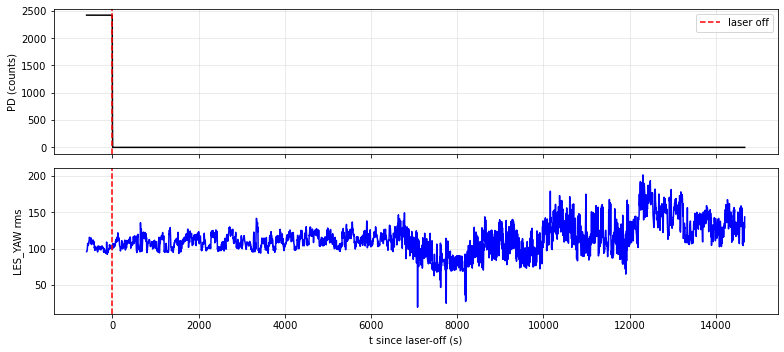

In [2]:
blk = int(5*fs)
n = len(pd_)//blk
tb = np.array([t[i*blk] for i in range(n)])
pdb = np.array([pd_[i*blk:(i+1)*blk].mean() for i in range(n)])

on = pdb > 50
i0, i1 = np.argmax(on), len(on)-1-np.argmax(on[::-1])
print(f'PD ON  mean  {pdb[on].mean():.1f} counts  (laser-on segment)')
print(f'PD OFF mean  {pdb[~on][pdb[~on].size>0 and slice(None)].mean() if (~on).any() else float("nan"):.2f} counts  (dark)')
print(f'transition block t = {tb[np.argmax(~on)]:+.0f} s  (documented: t=0 by construction of STOP)')

fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].plot(tb, pdb, 'k-'); ax[0].set_ylabel('PD (counts)')
ax[0].axvline(0, color='r', ls='--', label='laser off'); ax[0].legend()
lb = np.array([les[i*blk:(i+1)*blk].std() for i in range(n)])
ax[1].plot(tb, lb, 'b-'); ax[1].set_ylabel('LES_YAW rms'); ax[1].set_xlabel('t since laser-off (s)')
ax[1].axvline(0, color='r', ls='--')
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 2. Spectrogram -- the rotation line over the full coast-down

The line should fall smoothly after laser-off. Where it breaks up (if it does inside
this shorter 4.2 h record) marks the end of clean rotation.

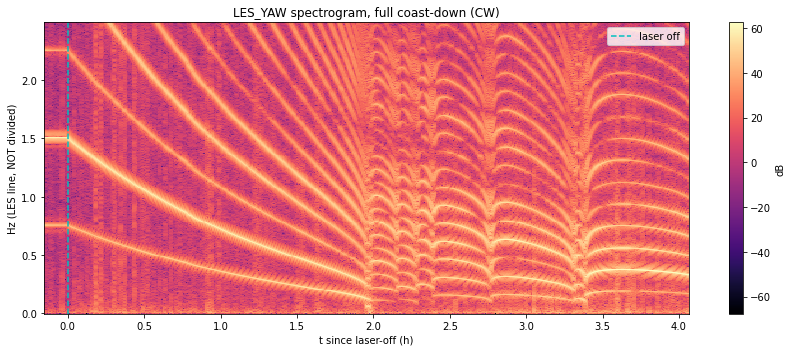

In [3]:
# decimate to 16 Hz -- rotation/libration lines are all below a few Hz
y16 = decimate(decimate(les - les.mean(), 8, ftype='fir'), 8, ftype='fir')
fs16 = fs/64
f_, t_, S = spectrogram(y16, fs16, nperseg=int(120*fs16), noverlap=int(90*fs16))
t_rel = t_ + t[0]
m = f_ < 2.5
plt.figure(figsize=(12, 5))
plt.pcolormesh(t_rel/3600, f_[m], 10*np.log10(S[m]+1e-12), shading='auto', cmap='magma')
plt.axvline(0, color='c', ls='--', lw=1.5, label='laser off')
plt.ylabel('Hz (LES line, NOT divided)'); plt.xlabel('t since laser-off (h)')
plt.colorbar(label='dB'); plt.legend(loc='upper right'); plt.title('LES_YAW spectrogram, full coast-down (CW)')
plt.tight_layout(); plt.show()

## 3. The divisor -- carried over from 09-13

09-13's divisor was settled by a live timed count on 2026-09-14: **rotation = line/2**
(the sail's 2-fold silhouette, not a spectral choice -- see that notebook's header).
The fold comes from the shape of what crosses the beam, which **does not depend on the
spin direction**, so DIVISOR = 2 carries over to this CW run.

The harmonic table below is kept as a sanity check: the odd harmonics of `line0/2`
should again be well down on the even ones. If they are not, the LES geometry changed
between runs and the divisor needs re-checking before trusting §9's absolute numbers.
(τ and the model verdict are divisor-invariant either way -- §7.)

In [4]:
# Clean stretch shortly after laser-off, before any decay-related smearing.
seg = (t > 30) & (t < 300)
y16seg = decimate(decimate(les[seg]-les[seg].mean(), 8, ftype='fir'), 8, ftype='fir')
fw, Pw = welch(y16seg, fs16, nperseg=len(y16seg), noverlap=0); dfw = fw[1]-fw[0]

def amp_at(f0, hw=0.01):
    mm = (fw > f0-hw) & (fw < f0+hw)
    return np.sqrt(2*Pw[mm].sum()*dfw) if mm.any() else 0.0

mm = (fw > 0.3) & (fw < 3.0)
line0 = fw[mm][np.argmax(Pw[mm])]
print(f'dominant LES line: {line0:.4f} Hz\n')
print(f'  hyp A (rotation = line)   -> f_rot = {line0:.4f} Hz, {1/line0:.3f} s/turn')
print(f'  hyp B (rotation = line/2) -> f_rot = {line0/2:.4f} Hz, {2/line0:.3f} s/turn')

print(f'\nharmonics of the hyp-B candidate fundamental (line0/2 = {line0/2:.4f} Hz):')
print(f'{"k":>3} {"freq":>9} {"amp":>10}  parity')
for k in range(1, 9):
    a_ = amp_at(line0/2*k)
    bar = '#'*int(46*a_/max(amp_at(line0), 1e-9))
    print(f'{k:3d} {line0/2*k:9.4f} {a_:10.2f}  {"even" if k%2==0 else "odd ":>4} |{bar}')
print('\nOn 09-13 odd k were ~10-30x down from even k. Spectrally that cannot separate')
print('hyp A from hyp B; the 2026-09-14 live count settled it as hyp B.')

# Resolved 2026-09-14 (live timing, see spindown_20260913.ipynb). The 2-fold
# silhouette is direction-independent, so it carries over to this CW run.
DIVISOR = 2.0
print(f'\nUsing DIVISOR = {DIVISOR} (hyp B, confirmed 2026-09-14) for the tracker below.')

dominant LES line: 1.4556 Hz

  hyp A (rotation = line)   -> f_rot = 1.4556 Hz, 0.687 s/turn
  hyp B (rotation = line/2) -> f_rot = 0.7278 Hz, 1.374 s/turn

harmonics of the hyp-B candidate fundamental (line0/2 = 0.7278 Hz):
  k      freq        amp  parity
  1    0.7278      26.76  odd  |############
  2    1.4556      96.68  even |##############################################
  3    2.1833      12.80  odd  |######
  4    2.9111      32.54  even |###############
  5    3.6389      10.78  odd  |#####
  6    4.3667       9.34  even |####
  7    5.0944       1.98  odd  |
  8    5.8222       9.71  even |####

On 09-13 odd k were ~10-30x down from even k. Spectrally that cannot separate
hyp A from hyp B; the 2026-09-14 live count settled it as hyp B.

Using DIVISOR = 2.0 (hyp B, confirmed 2026-09-14) for the tracker below.


## 4. Track the rotation frequency

Band-following peak tracker with parabolic sub-bin interpolation (same method as
`spindown_20260909`), run over the **entire 4.2 h record** rather than a hand-picked
window, so wherever the tracker loses the line is itself informative.

In [5]:
def peak_in_band(x, fsx, lo, hi):
    ac = x - x.mean()
    X = np.abs(np.fft.rfft(ac*np.hanning(len(ac))))
    fr = np.fft.rfftfreq(len(ac), 1/fsx)
    m = (fr > lo) & (fr < hi)
    if not m.any(): return np.nan, 0.0
    i = np.flatnonzero(m)[np.argmax(X[m])]
    if i == 0 or i >= len(X)-1: return fr[i], 0.0
    y0, y1, y2 = X[i-1], X[i], X[i+1]
    den = y0 - 2*y1 + y2
    fpk = fr[i] + (0.5*(y0-y2)/den if den else 0)*(fr[1]-fr[0])
    snr = X[i]/(np.median(X[max(0,i-60):i+60]) or 1)
    return fpk, snr

WIN, STEP = 150.0, 60.0          # s per estimate, s between estimates
nw, sw = int(WIN*fs16), int(STEP*fs16)
t16 = t[0] + np.arange(len(y16))/fs16

rows = []
track = line0
for i in range(0, len(y16)-nw, sw):
    tc = t16[i] + WIN/2
    if tc < 10: continue          # skip the laser-off transient
    # Floor + sign guard: a bad interpolated peak must not collapse the search
    # band to empty (found on 09-13 -- a 09-09-style tracker over 2 h never
    # hit it, but a noisy 16 h record does, around the eventual capture region).
    fpk, snr = peak_in_band(y16[i:i+nw], fs16, max(track*0.80, 0.02), track*1.15)
    if np.isnan(fpk) or fpk <= 0: continue
    blkk = y16[i:i+nw]
    rows.append((tc, fpk, fpk/DIVISOR, snr, blkk.std(), kurtosis(blkk), skew(blkk)))
    track = fpk

T    = np.array([r[0] for r in rows]); LINE = np.array([r[1] for r in rows])
FR   = np.array([r[2] for r in rows]); SNR  = np.array([r[3] for r in rows])
RMS  = np.array([r[4] for r in rows]); KURT = np.array([r[5] for r in rows])
SKW  = np.array([r[6] for r in rows])
print(f'{len(T)} estimates, t = {T[0]:.0f} .. {T[-1]:.0f} s ({T[-1]/3600:.2f} h of {t[-1]/3600:.2f} h)')
if T[-1] < t[-1]*0.99:
    print(f'\n*** tracker lost the line for good at t={T[-1]:.0f}s -- see \u00a78 for why. ***')

243 estimates, t = 15 .. 14595 s (4.05 h of 4.08 h)


## 5. Which points are trustworthy?

Same three criteria as `spindown_20260909`:
- **SNR** -- once the line dies the tracker still returns whatever is loudest.
- **Monotonic** -- a freely decaying rotor cannot speed up; an upward step means the
  tracker jumped.
- **State (kurtosis)** -- rotating gives a sinusoid-like waveform (kurtosis ~ -1.43);
  librating folds about the turning points (kurtosis rising toward +0.9 at large
  amplitude). Not reliable at small libration amplitude, so only the *first*
  transition found this way is trusted.

**CW-run adjustment:** today's rotating waveform is less sinusoidal than 09-13's --
kurtosis bounces between about -0.88 and -1.35 while SNR stays at 30-400 -- so 09-13's
`KURT_ROT = -1.0` trips at 0.92 h with the rotor clearly still rotating (§8 table; the
real transition is ~2.0 h, where SNR collapses to ~3 and kurtosis jumps to +1.5). Here
the cutoff is loosened to -0.8 and the fit is capped explicitly at `T_FIT_MAX = 1.5 h`,
well inside the clean rotation.

90 of 243 points kept
kept t = 15 .. 5355 s (1.48 h)
frequency 0.75039 -> 0.24199 Hz (67.8% decay)

fit window stopped at the T_FIT_MAX = 1.5 h cap.


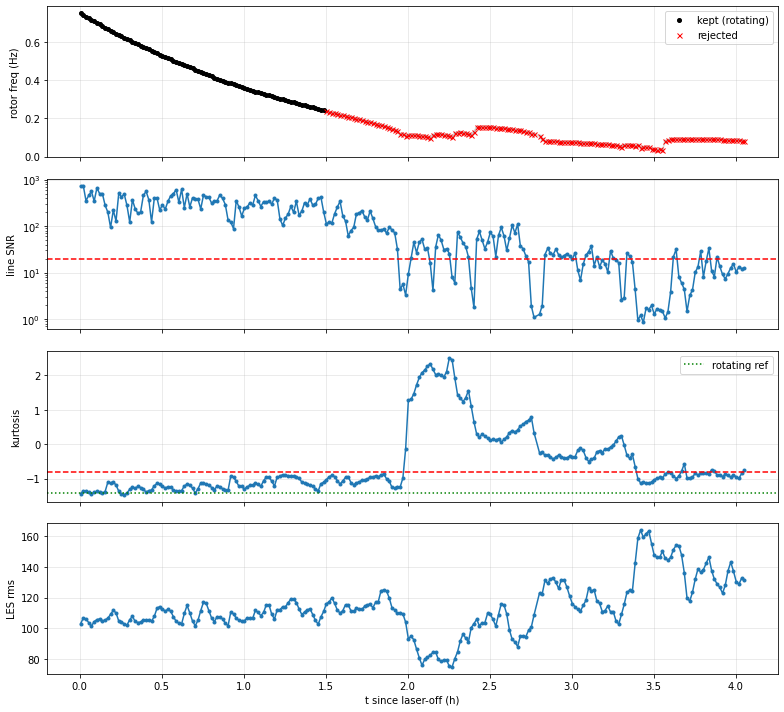

In [6]:
SNR_MIN  = 20.0
KURT_ROT = -0.8         # 09-13 used -1.0; see the note above
MAX_SKIP = 3
T_FIT_MAX = 1.5*3600    # s; explicit cap, inside the clean rotation (transition ~2.0 h)

good = np.zeros(len(FR), bool)
start = int(np.argmax(SNR > SNR_MIN))
runmin, capture_i, skips = np.inf, None, 0
for k in range(start, len(FR)):
    if T[k] > T_FIT_MAX: break
    if SNR[k] <= SNR_MIN:
        skips += 1
        if skips > MAX_SKIP: break
        continue
    skips = 0
    if KURT[k] > KURT_ROT:
        capture_i = k; break
    if FR[k] > runmin*1.02:
        break
    good[k] = True
    runmin = min(runmin, FR[k])

print(f'{good.sum()} of {len(good)} points kept')
print(f'kept t = {T[good].min():.0f} .. {T[good].max():.0f} s '
      f'({(T[good].max()-T[good].min())/3600:.2f} h)')
print(f'frequency {FR[good].max():.5f} -> {FR[good].min():.5f} Hz '
      f'({100*(1-FR[good].min()/FR[good].max()):.1f}% decay)')
if capture_i is not None:
    print(f'\nstate flag trips at t = {T[capture_i]:.0f} s '
          f'({T[capture_i]/3600:.2f} h), kurtosis {KURT[capture_i]:+.3f}')
elif T[good].max() + STEP > T_FIT_MAX:
    print(f'\nfit window stopped at the T_FIT_MAX = {T_FIT_MAX/3600:.1f} h cap.')
else:
    print('\nrecord ended (SNR dropout run) before the kurtosis state flag tripped --')
    print('see \u00a78: this is a gradual fade, not a single clean capture event.')

fig, ax = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
ax[0].plot(T/3600, FR, 'o-', alpha=.3, color='gray', ms=3)
ax[0].plot(T[good]/3600, FR[good], 'ko', ms=4, label='kept (rotating)')
ax[0].plot(T[~good]/3600, FR[~good], 'rx', ms=5, label='rejected')
ax[0].set_ylabel('rotor freq (Hz)'); ax[0].legend()
ax[1].semilogy(T/3600, SNR, 'o-', ms=3); ax[1].axhline(SNR_MIN, color='r', ls='--'); ax[1].set_ylabel('line SNR')
ax[2].plot(T/3600, KURT, 'o-', ms=3); ax[2].axhline(KURT_ROT, color='r', ls='--')
ax[2].axhline(-1.43, color='g', ls=':', label='rotating ref'); ax[2].set_ylabel('kurtosis'); ax[2].legend()
ax[3].plot(T/3600, RMS, 'o-', ms=3); ax[3].set_ylabel('LES rms'); ax[3].set_xlabel('t since laser-off (h)')
for a in ax:
    a.grid(alpha=.3)
    if capture_i is not None: a.axvline(T[capture_i]/3600, color='m', ls='-.', alpha=.7)
plt.tight_layout(); plt.show()

## 6. Exponential vs linear

This is what the run is for.

EXPONENTIAL  tau =   79.0 min   f0 = 0.76683 Hz   residual 5.0375 mHz
LINEAR       -0.0940 mHz/s   f0 = 0.71142 Hz   residual 17.0487 mHz

ratio of residuals (linear/exponential) = 3.384
  < 1 favours linear (constant torque); > 1 favours exponential (viscous)


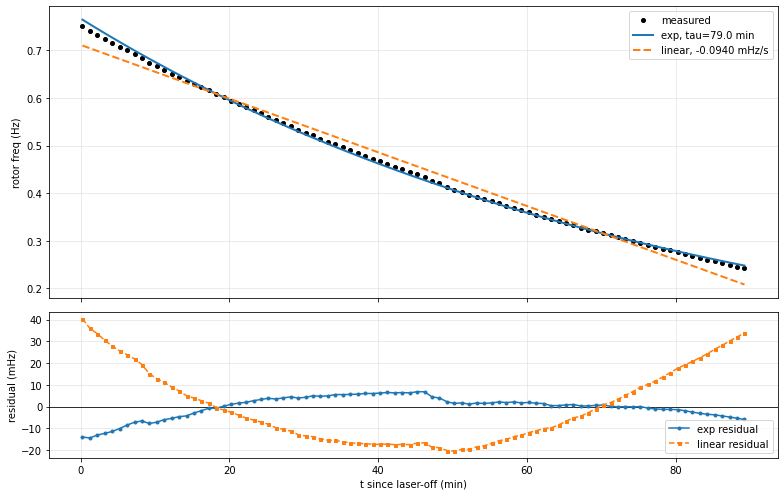


tau vs fit window (exponential is window-independent if correct):
 cutoff s    n  decay %   tau min
      615   11     11.2      85.9
     1563   26     25.2      86.1
     2511   42     38.5      84.7
     3459   58     50.2      82.1
     4407   74     59.6      80.5
     5355   90     67.8      79.0


In [7]:
tg, fg = T[good], FR[good]
pe = np.polyfit(tg, np.log(fg), 1); tau = -1/pe[0]; f0e = np.exp(pe[1])
fit_e = f0e*np.exp(-tg/tau)
pl = np.polyfit(tg, fg, 1); fit_l = np.polyval(pl, tg)
rms_e = np.sqrt(np.mean((fg-fit_e)**2)); rms_l = np.sqrt(np.mean((fg-fit_l)**2))

print(f'EXPONENTIAL  tau = {tau/60:6.1f} min   f0 = {f0e:.5f} Hz   residual {rms_e*1e3:.4f} mHz')
print(f'LINEAR       {pl[0]*1e3:7.4f} mHz/s   f0 = {pl[1]:.5f} Hz   residual {rms_l*1e3:.4f} mHz')
print(f'\nratio of residuals (linear/exponential) = {rms_l/rms_e:.3f}')
print('  < 1 favours linear (constant torque); > 1 favours exponential (viscous)')

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                       gridspec_kw={'height_ratios':[2,1]})
ax[0].plot(tg/60, fg, 'ko', ms=4, label='measured')
ax[0].plot(tg/60, fit_e, '-',  lw=2, label=f'exp, tau={tau/60:.1f} min')
ax[0].plot(tg/60, fit_l, '--', lw=2, label=f'linear, {pl[0]*1e3:.4f} mHz/s')
ax[0].set_ylabel('rotor freq (Hz)'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].axhline(0, color='k', lw=.8)
ax[1].plot(tg/60, (fg-fit_e)*1e3, 'o-',  ms=3, label='exp residual')
ax[1].plot(tg/60, (fg-fit_l)*1e3, 's--', ms=3, label='linear residual')
ax[1].set_ylabel('residual (mHz)'); ax[1].set_xlabel('t since laser-off (min)'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print('\ntau vs fit window (exponential is window-independent if correct):')
print(f'{"cutoff s":>9} {"n":>4} {"decay %":>8} {"tau min":>9}')
for cut in np.linspace(tg.min()+600, tg.max(), 6):
    mcut = tg <= cut
    if mcut.sum() < 5: continue
    p_ = np.polyfit(tg[mcut], np.log(fg[mcut]), 1)
    print(f'{cut:9.0f} {mcut.sum():4d} {100*(1-fg[mcut].min()/fg[mcut].max()):8.1f} {-1/p_[0]/60:9.1f}')

## 7. Can these models be distinguished here? (+ divisor invariance)

The usual decay-fraction separation test, plus the 09-13 check that the divisor
cannot change the verdict: a uniform rescaling `f -> f/D` rescales `fit_e`, `fit_l`
and both residual arrays by the same `1/D`, so **`-1/tau` and `rms_l/rms_e` are exactly
invariant to D**; only `f0`, the linear rate and §9's N*m numbers scale with `1/D`.

In [8]:
frac = 1 - fg.min()/fg.max()
curv = 0.5*frac**2*fg.max()
sep  = curv/min(rms_e, rms_l)
print(f'fractional decay observed : {100*frac:.1f}%')
print(f'separation ratio          : {sep:.1f}   (need >> 1 to distinguish)')
if sep < 3:
    print('\n*** NOT DISTINGUISHABLE. ***')
else:
    win = 'EXPONENTIAL (viscous)' if rms_e < rms_l else 'LINEAR (constant torque)'
    print(f'\n=> DISTINGUISHABLE: the data favour {win}')
    print(f'   by a residual ratio of {max(rms_l/rms_e, rms_e/rms_l):.2f}.')

print('\n--- divisor-invariance check: rerun \u00a75-6 with DIVISOR=1 (hyp A) ---')
FR1 = LINE
good1 = np.zeros(len(FR1), bool)
start = int(np.argmax(SNR > SNR_MIN))
runmin1, skips1 = np.inf, 0
for k in range(start, len(FR1)):
    if T[k] > T_FIT_MAX: break
    if SNR[k] <= SNR_MIN:
        skips1 += 1
        if skips1 > MAX_SKIP: break
        continue
    skips1 = 0
    if KURT[k] > KURT_ROT: break
    if FR1[k] > runmin1*1.02: break
    good1[k] = True
    runmin1 = min(runmin1, FR1[k])
tg1, fg1 = T[good1], FR1[good1]
pe1 = np.polyfit(tg1, np.log(fg1), 1); tau1 = -1/pe1[0]
pl1 = np.polyfit(tg1, fg1, 1)
fit_e1 = np.exp(pe1[1])*np.exp(-tg1/tau1); fit_l1 = np.polyval(pl1, tg1)
rms_e1 = np.sqrt(np.mean((fg1-fit_e1)**2)); rms_l1 = np.sqrt(np.mean((fg1-fit_l1)**2))
print(f'  DIVISOR=1 (hyp A): n={good1.sum():3d}  tau={tau1/60:6.2f} min  '
      f'f0={np.exp(pe1[1]):.4f} Hz  resid ratio(l/e)={rms_l1/rms_e1:.3f}')
print(f'  DIVISOR=2 (hyp B): n={good.sum():3d}  tau={tau/60:6.2f} min  '
      f'f0={f0e:.4f} Hz  resid ratio(l/e)={rms_l/rms_e:.3f}')
print('\n  tau and the residual ratio should match exactly -- the model verdict and tau')
print('  do not depend on the divisor. f0 and the linear-model rate differ by exactly')
print('  the factor of 2, which is why \u00a79 relies on DIVISOR=2 being right.')

fractional decay observed : 67.8%
separation ratio          : 34.2   (need >> 1 to distinguish)

=> DISTINGUISHABLE: the data favour EXPONENTIAL (viscous)
   by a residual ratio of 3.38.

--- divisor-invariance check: rerun §5-6 with DIVISOR=1 (hyp A) ---
  DIVISOR=1 (hyp A): n= 90  tau= 79.04 min  f0=1.5337 Hz  resid ratio(l/e)=3.384
  DIVISOR=2 (hyp B): n= 90  tau= 79.04 min  f0=0.7668 Hz  resid ratio(l/e)=3.384

  tau and the residual ratio should match exactly -- the model verdict and tau
  do not depend on the divisor. f0 and the linear-model rate differ by exactly
  the factor of 2, which is why §9 relies on DIVISOR=2 being right.


## 8. Past the clean segment

What the tracker sees after the last kept point. On 09-13 this was a gradual,
multi-stage fade with intermittent SNR dropouts rather than one clean capture; this
record is 4x shorter, so it may end before the rotor gets that far.

In [9]:
w = (T > T[good].max()-300) & (T < T[good].max()+4200)
print(f'{"t (s)":>8} {"t (h)":>6} {"line":>9} {"as f/2":>9} {"SNR":>8} {"kurt":>8} {"skew":>8}')
for k in np.flatnonzero(w)[::3]:
    mark = '  <-- last kept' if T[k] == T[good].max() else ''
    print(f'{T[k]:8.0f} {T[k]/3600:6.2f} {LINE[k]:9.4f} {LINE[k]/2:9.4f} '
          f'{SNR[k]:8.2f} {KURT[k]:+8.3f} {SKW[k]:+8.3f}{mark}')

print(f'\nTracker coverage: T runs to {T.max():.0f} s ({T.max()/3600:.2f} h) of the full '
      f'{t[-1]/3600:.2f} h record.')
if T.max() < t[-1]*0.99:
    print(f'It loses the line for good around there because the WIN={WIN:.0f} s window\'s')
    print(f'frequency resolution (~{1/WIN*1e3:.1f} mHz) becomes comparable to the signal')
    print('itself deep in the transition -- a real method limit, not a bug to paper over.')
    print('A rotation-vs-libration-aware tracker (flagged TODO in')
    print('analysis/dataset_20260911_drive_spindown.md) needs either a longer window there or a purpose-built')
    print('approach -- lab_utils/monitor_libration.py / watch_capture.py, not this')
    print('generic band-follower.')

   t (s)  t (h)      line    as f/2      SNR     kurt     skew
    5115   1.42    0.5140    0.2570   281.78   -1.221   -0.254
    5295   1.47    0.4914    0.2457   415.69   -1.148   -0.225
    5475   1.52    0.4686    0.2343   121.96   -0.947   -0.039
    5655   1.57    0.4469    0.2235   255.80   -1.060   -0.118
    5835   1.62    0.4253    0.2126   128.01   -0.963   -0.026
    6015   1.67    0.4038    0.2019    93.96   -1.178   -0.145
    6195   1.72    0.3811    0.1906   216.27   -1.045   -0.092
    6375   1.77    0.3594    0.1797   211.76   -0.951   -0.015
    6555   1.82    0.3347    0.1674    81.03   -0.957   +0.015
    6735   1.87    0.3101    0.1550    70.55   -1.003   +0.089
    6915   1.92    0.2795    0.1398    71.71   -1.277   -0.055
    7095   1.97    0.2401    0.1201     5.67   -0.980   -0.257
    7275   2.02    0.2247    0.1123    20.50   +1.306   -0.397
    7455   2.07    0.2193    0.1097    45.69   +1.938   -0.931
    7635   2.12    0.2064    0.1032    33.88   +2.268  

## 9. Physical consequences

`I = 1.1e-11 kg m^2` (+-10%): weighed 7 mg assembly + model shape, adopted 2026-09-30
(CLAUDE.md). **Not** 09-13's `1.88e-11`, which is superseded -- 09-13's printed torques
are x1.71 too high, so §10 rescales them before comparing. Every torque here scales
linearly with I; tau does not depend on it.

In [10]:
I = 1.1e-11           # kg m^2, +-10%. Weighed mass + model shape (CLAUDE.md, 2026-09-30).

print(f'IF VISCOUS (tau = {tau/60:.1f} min):')
for fr_ in (0.1, 0.3, 0.5, f0e):
    drag = I*2*np.pi*fr_/tau
    print(f'  drag at {fr_:.3f} Hz = {drag:.3e} N m')
print(f'\nIF CONSTANT TORQUE (for comparison):')
dt = I*2*np.pi*abs(pl[0])
print(f'  drag torque = {dt:.3e} N m, speed-independent')

IF VISCOUS (tau = 79.0 min):
  drag at 0.100 Hz = 1.457e-15 N m
  drag at 0.300 Hz = 4.372e-15 N m
  drag at 0.500 Hz = 7.287e-15 N m
  drag at 0.767 Hz = 1.118e-14 N m

IF CONSTANT TORQUE (for comparison):
  drag torque = 6.496e-15 N m, speed-independent


## 10. CW (today) vs CCW (09-13)

Purely viscous drag is symmetric in the spin direction, so it predicts the **same tau
both ways**. A tau or f0 difference larger than the window-to-window scatter in §6 is
an observation worth chasing (a direction-dependent torque, e.g. residual laser light,
gas flow, or a fixed-sign background torque, would appear as one), but by itself it
does not say which.

09-13 numbers are copied from that notebook's saved outputs (DIVISOR=2, 103 kept
points); its torques are rescaled to today's `I`.

                              09-13 CCW     10-11 CW
tau (min)                          79.8         79.0
f0 of exp fit (Hz)               0.7999       0.7668
decay in kept window (%)           72.5         67.8
resid ratio lin/exp                4.24         3.38
linear rate (mHz/s)             -0.0907      -0.0940
viscous drag @ 0.1 Hz (N m)    1.444e-15    1.457e-15
viscous drag @ 0.3 Hz (N m)    4.331e-15    4.372e-15
viscous drag @ 0.5 Hz (N m)    7.218e-15    7.287e-15

tau ratio CW/CCW = 0.990


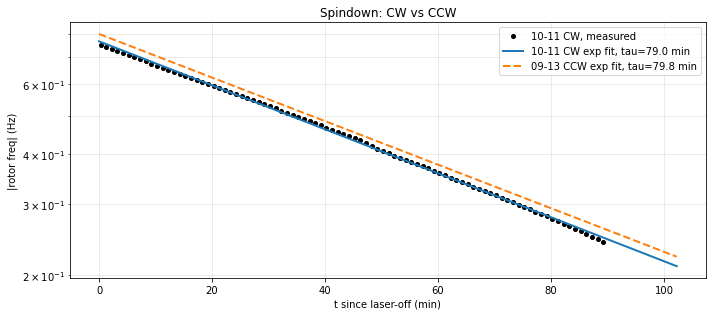

In [11]:
CCW = dict(tau_min=79.8, f0=0.79993, decay=72.5, ratio=4.236, lin_rate=-0.0907e-3,
           I_used=1.88e-11)
CW  = dict(tau_min=tau/60, f0=f0e, decay=100*frac, ratio=rms_l/rms_e, lin_rate=pl[0])

print(f'{"":26s} {"09-13 CCW":>12s} {"10-11 CW":>12s}')
print(f'{"tau (min)":26s} {CCW["tau_min"]:12.1f} {CW["tau_min"]:12.1f}')
print(f'{"f0 of exp fit (Hz)":26s} {CCW["f0"]:12.4f} {CW["f0"]:12.4f}')
print(f'{"decay in kept window (%)":26s} {CCW["decay"]:12.1f} {CW["decay"]:12.1f}')
print(f'{"resid ratio lin/exp":26s} {CCW["ratio"]:12.2f} {CW["ratio"]:12.2f}')
print(f'{"linear rate (mHz/s)":26s} {CCW["lin_rate"]*1e3:12.4f} {CW["lin_rate"]*1e3:12.4f}')
for fr_ in (0.1, 0.3, 0.5):
    d_ccw = I*2*np.pi*fr_/(CCW['tau_min']*60)
    d_cw  = I*2*np.pi*fr_/tau
    print(f'{"viscous drag @ %.1f Hz (N m)" % fr_:26s} {d_ccw:12.3e} {d_cw:12.3e}')
print(f'\ntau ratio CW/CCW = {CW["tau_min"]/CCW["tau_min"]:.3f}')

fig, ax = plt.subplots(figsize=(10, 4.5))
tt = np.linspace(0, max(tg.max(), 6135), 300)
ax.plot(tg/60, fg, 'ko', ms=4, label='10-11 CW, measured')
ax.plot(tt/60, f0e*np.exp(-tt/tau), '-', lw=2, label=f'10-11 CW exp fit, tau={tau/60:.1f} min')
ax.plot(tt/60, CCW['f0']*np.exp(-tt/(CCW['tau_min']*60)), '--', lw=2,
        label=f'09-13 CCW exp fit, tau={CCW["tau_min"]:.1f} min')
ax.set_yscale('log'); ax.set_xlabel('t since laser-off (min)'); ax.set_ylabel('|rotor freq| (Hz)')
ax.set_title('Spindown: CW vs CCW'); ax.legend(); ax.grid(alpha=.3, which='both')
plt.tight_layout(); plt.show()

## 11. Is the CW/CCW difference just the fit window?

§6's τ drifts downward as the window lengthens (86 -> 79 min), and 09-13 drifted the
same way (85 -> 80 min). So **a single-exponential τ is not one number**: it depends
on which speeds the window covers, and 82.6 vs 79.8 min (first pass) reflected the
windows as much as the runs. Matching *time* after laser-off is not fair either --
the runs started at different speeds (0.786 vs 0.750 Hz).

The fair comparison is at **matched speeds**. Below, both coast files go through the
**same** tracker and the **same** point selection (SNR > 20, monotonic, stop at the
first SNR collapse or kurtosis > +0.5 -- the clear libration signature, which avoids
the waveform-shape issue noted in §5). Then:

- (a) τ over the same time windows, for reference;
- (b) τ in matched **frequency** bands -- the real comparison;
- (c) a two-term fit, viscous + constant torque, `df/dt = -f/τ_visc - c`, over the
  common band. A constant term is the simplest thing that makes the single-exponential
  τ fall as the rotor slows.

Quoted ± are formal fit errors. Residuals are correlated between neighbouring
estimates (150 s windows every 60 s), so these **understate** the real uncertainty;
the band-to-band and window-to-window scatter is the better guide.

In [12]:
from scipy.optimize import curve_fit

def coast_track(gps_a, gps_b, stop):
    # §1 + §2 + §4 for an arbitrary coast file: load LES, decimate, band-follow.
    global GPS_A, GPS_B
    GPS_A, GPS_B = gps_a, gps_b                 # get_h5 builds filenames from these
    y, tt, fsx = load(get_h5(*WANT['les']))
    GPS_A, GPS_B = 1475768725, 1475784000       # restore this notebook's run
    ts = tt - stop
    yd = decimate(decimate(y - y.mean(), 8, ftype='fir'), 8, ftype='fir')
    fsd = fsx/64
    td = ts[0] + np.arange(len(yd))/fsd
    # starting line: dominant LES line 30-300 s after laser-off (as §3)
    s0 = (td > 30) & (td < 300)
    fw_, Pw_ = welch(yd[s0], fsd, nperseg=s0.sum(), noverlap=0)
    mm_ = (fw_ > 0.3) & (fw_ < 3.0)
    trk = fw_[mm_][np.argmax(Pw_[mm_])]
    nw_, sw_ = int(WIN*fsd), int(STEP*fsd)
    out = []
    for i in range(0, len(yd)-nw_, sw_):
        tc = td[i] + WIN/2
        if tc < 10: continue
        fpk, snr = peak_in_band(yd[i:i+nw_], fsd, max(trk*0.80, 0.02), trk*1.15)
        if np.isnan(fpk) or fpk <= 0: continue
        out.append((tc, fpk/DIVISOR, snr, kurtosis(yd[i:i+nw_])))
        trk = fpk
    return np.array(out).T

def clean_rotation(Tx, Fx, Sx, Kx, snr_min=20, kurt_lib=0.5, max_skip=3):
    # Identical selection for both runs: SNR, monotonic, stop at libration signature.
    keep = np.zeros(len(Tx), bool); rmin = np.inf; sk = 0
    for k in range(int(np.argmax(Sx > snr_min)), len(Tx)):
        if Sx[k] <= snr_min:
            sk += 1
            if sk > max_skip: break
            continue
        sk = 0
        if Kx[k] > kurt_lib or Fx[k] > rmin*1.02: break
        keep[k] = True; rmin = min(rmin, Fx[k])
    return Tx[keep], Fx[keep]

runs = {
    '09-13 CCW': coast_track(1473375897, 1473435502, 1473376497),
    '10-11 CW':  coast_track(1475768725, 1475784000, STOP),
}
RUNS = {k: clean_rotation(*v) for k, v in runs.items()}
for k, (Tx, Fx) in RUNS.items():
    print(f'{k}: clean rotation to {Tx.max()/3600:.2f} h, {Fx.max():.3f} -> {Fx.min():.3f} Hz, n={len(Tx)}')

09-13 CCW: clean rotation to 1.70 h, 0.786 -> 0.216 Hz, n=103
10-11 CW: clean rotation to 1.94 h, 0.750 -> 0.133 Hz, n=117


(a) SAME TIME WINDOW after laser-off -- tau (min)
      window        09-13 CCW        10-11 CW
    0-0.50 h       85.2 ± 0.3      85.8 ± 0.2
    0-0.90 h       84.3 ± 0.2      82.8 ± 0.3
    0-1.25 h       82.2 ± 0.2      80.4 ± 0.3
    0-1.50 h       81.2 ± 0.2      79.0 ± 0.3
    0-1.75 h              n/a      76.6 ± 0.4
    0-1.90 h              n/a      74.2 ± 0.5

(b) SAME FREQUENCY BAND -- tau (min), n points
   band (Hz)              09-13 CCW              10-11 CW
   0.50-0.75      85.7 ± 0.1 (n=35)     85.3 ± 0.2 (n=34)
   0.40-0.60      81.7 ± 0.4 (n=33)     80.4 ± 0.4 (n=32)
   0.30-0.50      78.9 ± 0.2 (n=40)     76.6 ± 0.2 (n=39)
   0.25-0.40      77.7 ± 0.3 (n=36)     75.8 ± 0.3 (n=35)
   0.15-0.30 not covered (min 0.22)     58.7 ± 0.9 (n=40)
   0.25-0.75      80.8 ± 0.2 (n=88)     79.3 ± 0.2 (n=86)


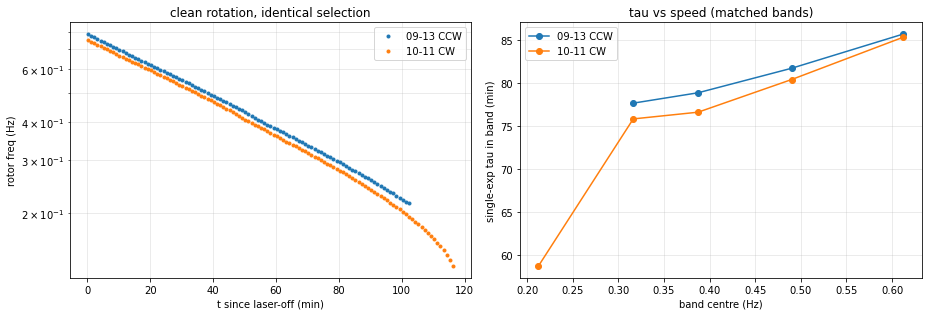

In [13]:
def tau_fit(Tx, Fx, m):
    p = np.polyfit(Tx[m], np.log(Fx[m]), 1)
    r = np.log(Fx[m]) - np.polyval(p, Tx[m])
    se = np.sqrt(np.sum(r**2)/(m.sum()-2)/np.sum((Tx[m]-Tx[m].mean())**2))
    return -1/p[0]/60, se/p[0]**2/60

names = list(RUNS)
print(f'(a) SAME TIME WINDOW after laser-off -- tau (min)')
print(f'{"window":>12} ' + ''.join(f'{n:>16}' for n in names))
for tmax in (0.5, 0.9, 1.25, 1.5, 1.75, 1.9):
    cells_ = []
    for n in names:
        Tx, Fx = RUNS[n]
        if Tx.max() < tmax*3600 - 120: cells_.append(f'{"n/a":>16}'); continue
        cells_.append('%10.1f ± %.1f' % tau_fit(Tx, Fx, Tx <= tmax*3600))
    print(f'{"0-%.2f h" % tmax:>12} ' + ''.join(f'{c:>16}' for c in cells_))

BANDS = [(0.50, 0.75), (0.40, 0.60), (0.30, 0.50), (0.25, 0.40), (0.15, 0.30), (0.25, 0.75)]
print(f'\n(b) SAME FREQUENCY BAND -- tau (min), n points')
print(f'{"band (Hz)":>12} ' + ''.join(f'{n:>22}' for n in names))
band_tau = {n: [] for n in names}
for lo, hi in BANDS:
    cells_ = []
    for n in names:
        Tx, Fx = RUNS[n]
        m = (Fx >= lo) & (Fx <= hi)
        # only call a band covered if the run actually reaches its bottom edge
        if m.sum() > 5 and Fx.min() <= lo*1.02:
            tv, te = tau_fit(Tx, Fx, m); band_tau[n].append(tv)
            cells_.append(f'{tv:6.1f} ± {te:.1f} (n={m.sum()})')
        else:
            band_tau[n].append(np.nan)
            cells_.append(f'not covered (min {Fx.min():.2f})')
    print(f'{"%.2f-%.2f" % (lo, hi):>12} ' + ''.join(f'{c:>22}' for c in cells_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for n in names:
    Tx, Fx = RUNS[n]
    ax[0].semilogy(Tx/60, Fx, 'o', ms=3, label=n)
    mids = [np.sqrt(lo*hi) for lo, hi in BANDS[:-1]]
    ax[1].plot(mids, band_tau[n][:-1], 'o-', label=n)
ax[0].set_xlabel('t since laser-off (min)'); ax[0].set_ylabel('rotor freq (Hz)')
ax[0].set_title('clean rotation, identical selection'); ax[0].legend(); ax[0].grid(alpha=.3, which='both')
ax[1].set_xlabel('band centre (Hz)'); ax[1].set_ylabel('single-exp tau in band (min)')
ax[1].set_title('tau vs speed (matched bands)'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [14]:
LO, HI = 0.25, 0.75     # common band both runs cover cleanly
print(f'(c) viscous + constant torque, df/dt = -f/tau_visc - c, fit over {LO}-{HI} Hz\n')
print(f'{"":>10} {"tau_visc (min)":>16} {"c (uHz/s)":>14} {"const torque (N m)":>20} {"resid (mHz)":>12} {"1-exp resid":>12}')
for n in names:
    Tx, Fx = RUNS[n]
    m = (Fx >= LO) & (Fx <= HI); t0 = Tx[m][0]
    def model(tt_, F0, tv, c):
        return (F0 + c*tv)*np.exp(-(tt_-t0)/tv) - c*tv
    pp, cv = curve_fit(model, Tx[m], Fx[m], p0=[Fx[m][0], 4800, 1e-6]); ee = np.sqrt(np.diag(cv))
    r2 = np.sqrt(np.mean((Fx[m] - model(Tx[m], *pp))**2))
    pe_ = np.polyfit(Tx[m], np.log(Fx[m]), 1)
    r1 = np.sqrt(np.mean((Fx[m] - np.exp(np.polyval(pe_, Tx[m])))**2))
    print(f'{n:>10} {pp[1]/60:9.0f} ± {ee[1]/60:<4.0f} {pp[2]*1e6:8.2f} ± {ee[2]*1e6:<4.2f}'
          f' {I*2*np.pi*pp[2]:20.2e} {r2*1e3:12.3f} {r1*1e3:12.3f}')
print(f'\nconst torque uses I = {I:.1e} kg m^2 (§9); tau_visc does not depend on I.')

(c) viscous + constant torque, df/dt = -f/tau_visc - c, fit over 0.25-0.75 Hz

             tau_visc (min)      c (uHz/s)   const torque (N m)  resid (mHz)  1-exp resid
 09-13 CCW        97 ± 1       15.18 ± 0.60             1.05e-15        1.156        3.817
  10-11 CW       100 ± 1       19.13 ± 0.72             1.32e-15        1.319        4.634

const torque uses I = 1.1e-11 kg m^2 (§9); tau_visc does not depend on I.


### What §11 says (as of first run, 2026-10-11)

- **Most of the first-pass CW/CCW difference was the window.** In matched speed bands
  the two runs agree to ~1-3% (e.g. 0.50-0.75 Hz: 85.7 vs 85.3 min; whole common band
  0.25-0.75 Hz: 80.8 vs 79.3 min).
- **τ falls with speed in both directions, with the same shape** (~85 min at 0.6 Hz ->
  ~77 min near 0.3 Hz). So there is no "best" window for a single exponential --
  any single τ is an average over the speeds the window spans.
- **CW sits 0.4-2.3 min shorter in every band.** That is consistent in sign and larger
  than the formal errors, but the formal errors understate the truth (correlated
  residuals); suggestive, not established, with one run each way.
- **Viscous + constant torque** describes both runs with the same viscous part
  (τ_visc ~97 vs ~100 min) and a constant drag of ~1e-15 N m, ~25% larger for CW.
  That constant term is what makes the single-exponential τ drift with window. Whether
  the CW/CCW difference in it is real needs repeat runs in each direction.
- The 0.15-0.30 Hz band is only covered by CW (09-13's clean rotation ends at 0.22 Hz),
  and sits near the libration transition where the tracker is least reliable.

## Conclusions

> **TODO -- fill in after review.** Placeholders follow the 09-13 structure.

1. **The damping model.** §6-7:
2. **tau.** §6, and how it compares with 09-13 CCW at matched speeds (§10-11):
3. **Where the clean record ends.** §8:

**Still open after this notebook:**

- The run facts flagged at the top (CW drive setup, `LASER_OFFSET`, electrode state).
- Whether any CW/CCW difference in §10 is larger than the fit-window scatter, and if so
  what direction-dependent torque would produce it.